# T11 ranker v1: figures
Every figure is regenerated from `data/` (written by `analysis.py` from `runs/ranker_v1/nohalf`). See README.md for the claims each one backs.

In [1]:
import os, sys, json
import pandas as pd
from IPython.display import Image, display
HERE = os.path.abspath('.')
sys.path.insert(0, HERE)
import figures as F
info = json.load(open('data/run_info.json'))
info['config'], info['thresholds']['rules'][info['pick']]

({'n_rot': 3000,
  'n_neg_train': 2100,
  'n_neg_sources': 700,
  'n_persistent_sources': 43,
  'n_neg_full': 743,
  'n_features': 138,
  'half': False,
  'neg_per_rot_train': 0.7,
  'r': 1.0,
  'half_in_features': [],
  'seconds': 49.24221639195457},
 {'<1d': 0.49236515164375305,
  '1-3d': 0.4790034294128418,
  '3-10d': 0.6645410656929016,
  '10-30d': 0.6129521131515503,
  '>30d': 0.7385467886924744,
  'none': inf})

## Headline table (all stars, per dev table)

In [2]:
s = pd.read_csv('data/summary_all.csv')
a = s[(s.bin == 'all') & s.rule.isin(['hand', 'rank_global', 'head_perbin', 'head_perbin_p0.86', 'head_none'])]
a.pivot_table(index=['set', 'mode', 'rule'], values=['success', 'wrong', 'alias', 'declined', 'neg_fp_rate']).round(3)

alias  declined  neg_fp_rate  \
set               mode     rule                                              
dev_medium        assigned hand               0.005     0.811        0.027   
                           head_none          0.074     0.000        1.000   
                           head_perbin        0.005     0.714        0.024   
                           head_perbin_p0.86  0.002     0.771        0.009   
                           rank_global        0.003     0.747        0.022   
                  fullyear hand               0.008     0.703        0.002   
                           head_none          0.054     0.000        1.000   
                           head_perbin        0.007     0.576        0.032   
                           head_perbin_p0.86  0.007     0.665        0.014   
                           rank_global        0.007     0.667        0.014   
dev_medium_b      assigned hand               0.002     0.811          NaN   
                           head_none          0.076     0.000          NaN   
                           head_perbin        0.004     0.708          NaN   
                           head_perbin_p0.86  0.002     0.767          NaN   
                           rank_global        0.003     0.747          NaN   
                  fullyear hand               0.009     0.687          NaN   
                           head_none          0.073     0.000          NaN   
                           head_perbin        0.014     0.565          NaN   
                           head_perbin_p0.86  0.006     0.651          NaN   
                           rank_global        0.007     0.660          NaN   
train_oof         assigned hand               0.003     0.802        0.030   
                           head_none          0.068     0.000        1.000   
                           head_perbin        0.005     0.708        0.035   
                           head_perbin_p0.86  0.002     0.766        0.014   
                           rank_global        0.004     0.738        0.034   
train_oof_negfull fullyear hand                 NaN       NaN        0.017   
                           head_none            NaN       NaN        1.000   
                           head_perbin          NaN       NaN        0.047   
                           head_perbin_p0.86    NaN       NaN        0.016   
                           rank_global          NaN       NaN        0.009   
train_oof_negpers assigned hand                 NaN       NaN        0.062   
                           head_none            NaN       NaN        1.000   
                           head_perbin          NaN       NaN        0.078   
                           head_perbin_p0.86    NaN       NaN        0.039   
                           rank_global          NaN       NaN        0.062   

                                              success  wrong  
set               mode     rule                               
dev_medium        assigned hand                 0.154  0.030  
                           head_none            0.333  0.593  
                           head_perbin          0.230  0.051  
                           head_perbin_p0.86    0.201  0.025  
                           rank_global          0.204  0.046  
                  fullyear hand                 0.270  0.019  
                           head_none            0.493  0.453  
                           head_perbin          0.364  0.054  
                           head_perbin_p0.86    0.312  0.016  
                           rank_global          0.299  0.027  
dev_medium_b      assigned hand                 0.168  0.019  
                           head_none            0.354  0.570  
                           head_perbin          0.253  0.035  
                           head_perbin_p0.86    0.218  0.013  
                           rank_global          0.224  0.026  
                  fullyear hand                 0.272  0.032  
                         

## Purity–completeness
Precision vs answer rate; markers are the named operating points (hand = star).

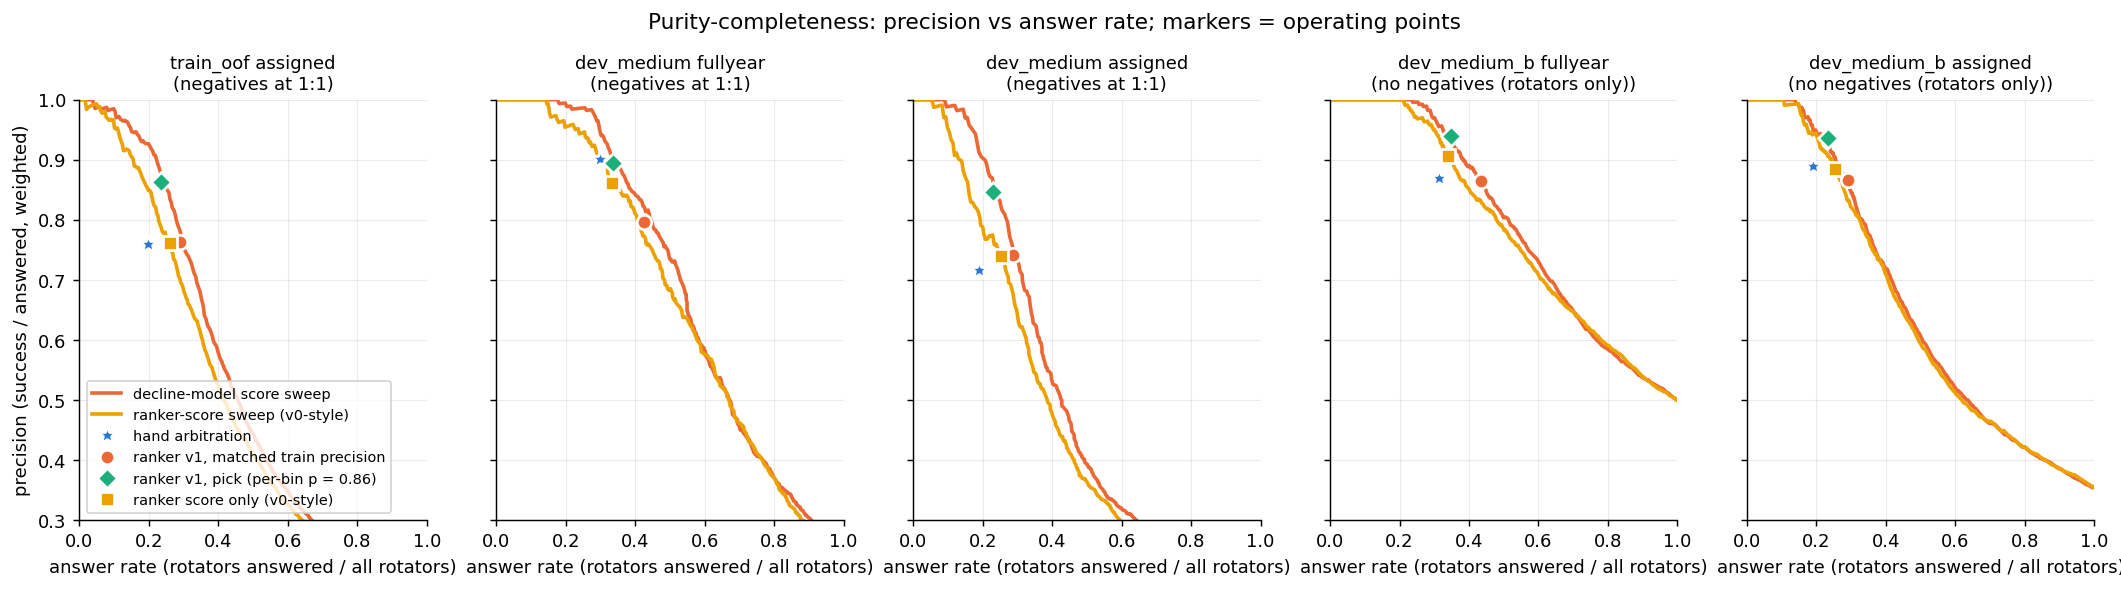

In [3]:
F.purity_completeness(); display(Image('figures/fig_purity_completeness.png'))

## Two-set tuning of the precision target

,family,tuned_on,judged_on,mode,pick,success,wrong,hand_success,hand_wrong,passes
0,head_perbin,dev_medium,dev_medium_b,fullyear,0.86,0.328,0.015,0.272,0.032,True
1,head_perbin,dev_medium,dev_medium_b,assigned,0.86,0.218,0.013,0.168,0.019,True
2,head_perbin,dev_medium_b,dev_medium,fullyear,0.84,0.324,0.030,0.270,0.019,False
3,head_perbin,dev_medium_b,dev_medium,assigned,0.84,0.209,0.029,0.154,0.030,True
4,head_global,dev_medium,dev_medium_b,fullyear,0.88,0.326,0.018,0.272,0.032,True
5,head_global,dev_medium,dev_medium_b,assigned,0.88,0.206,0.014,0.168,0.019,True
6,head_global,dev_medium_b,dev_medium,fullyear,0.85,0.338,0.031,0.270,0.019,False
7,head_global,dev_medium_b,dev_medium,assigned,0.85,0.212,0.030,0.154,0.030,True


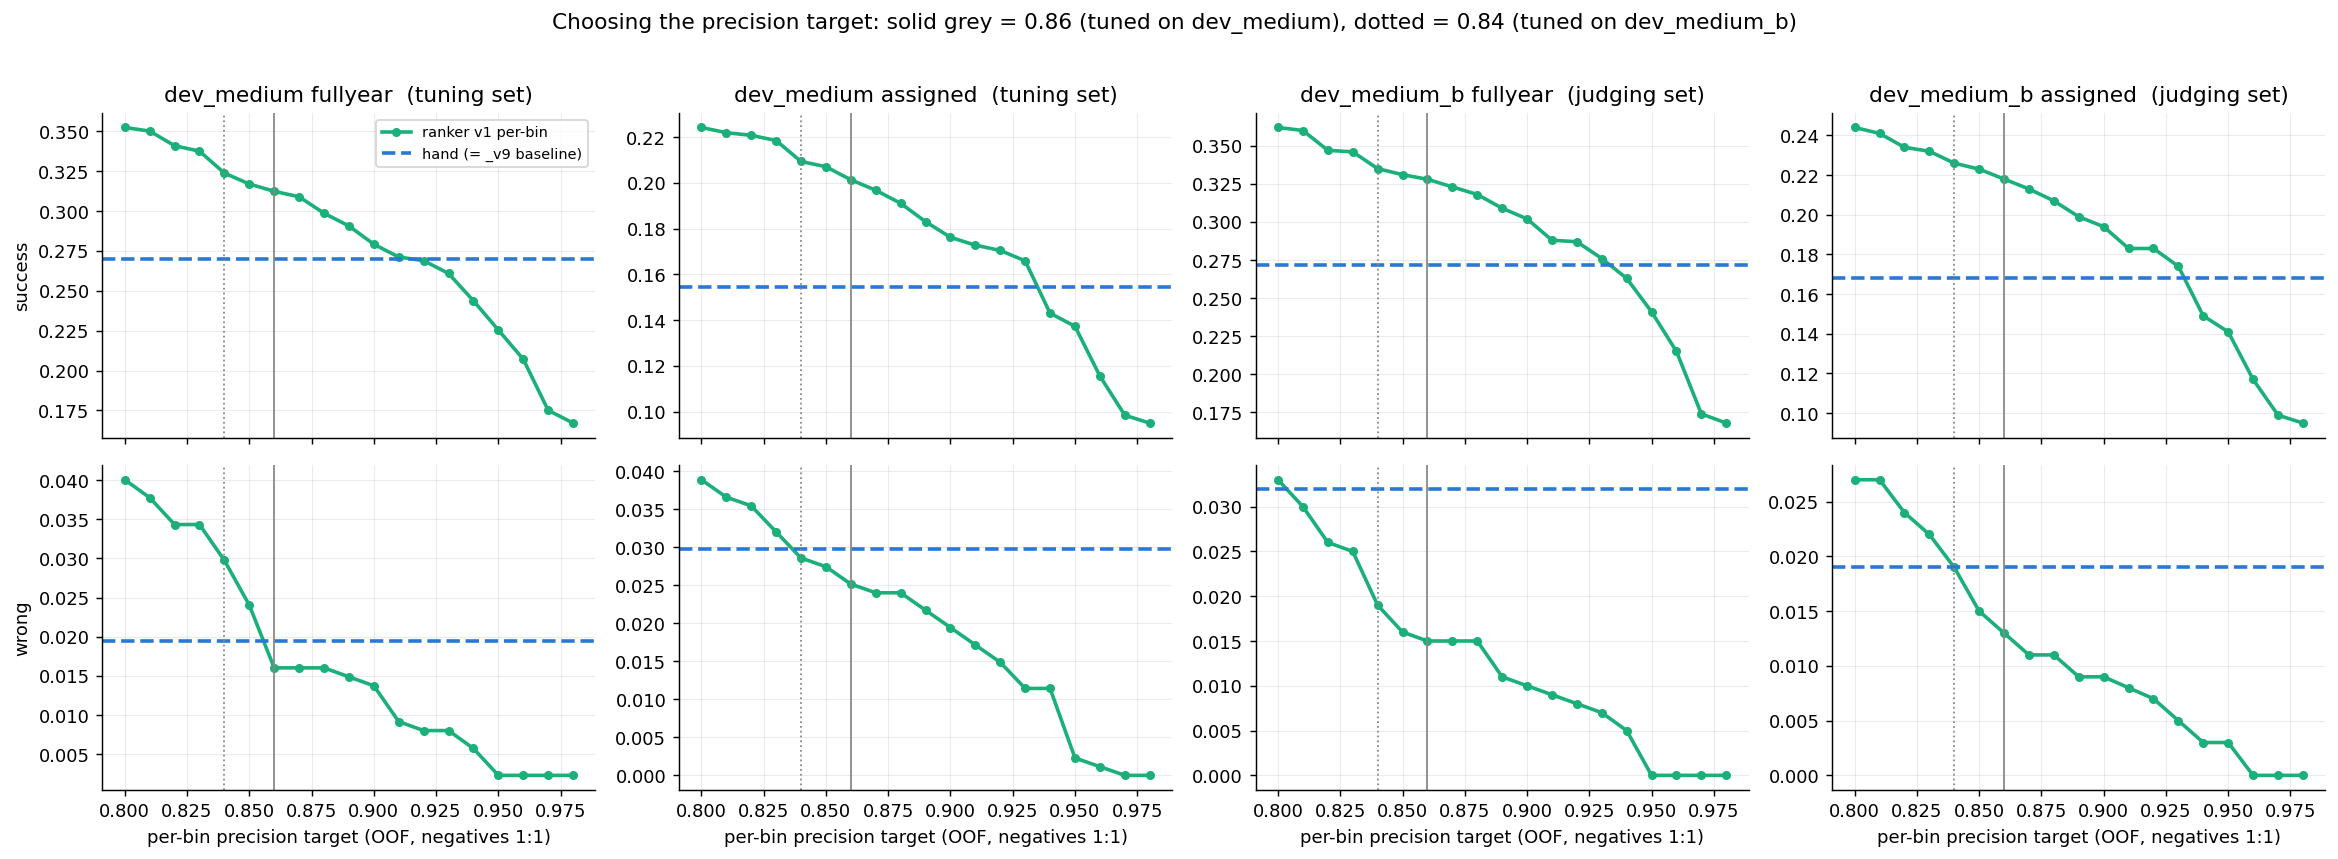

In [4]:
display(pd.read_csv('data/tuning.csv').round(3))
F.tuning(); display(Image('figures/fig_tuning.png'))

## Per period bin, ranker vs hand

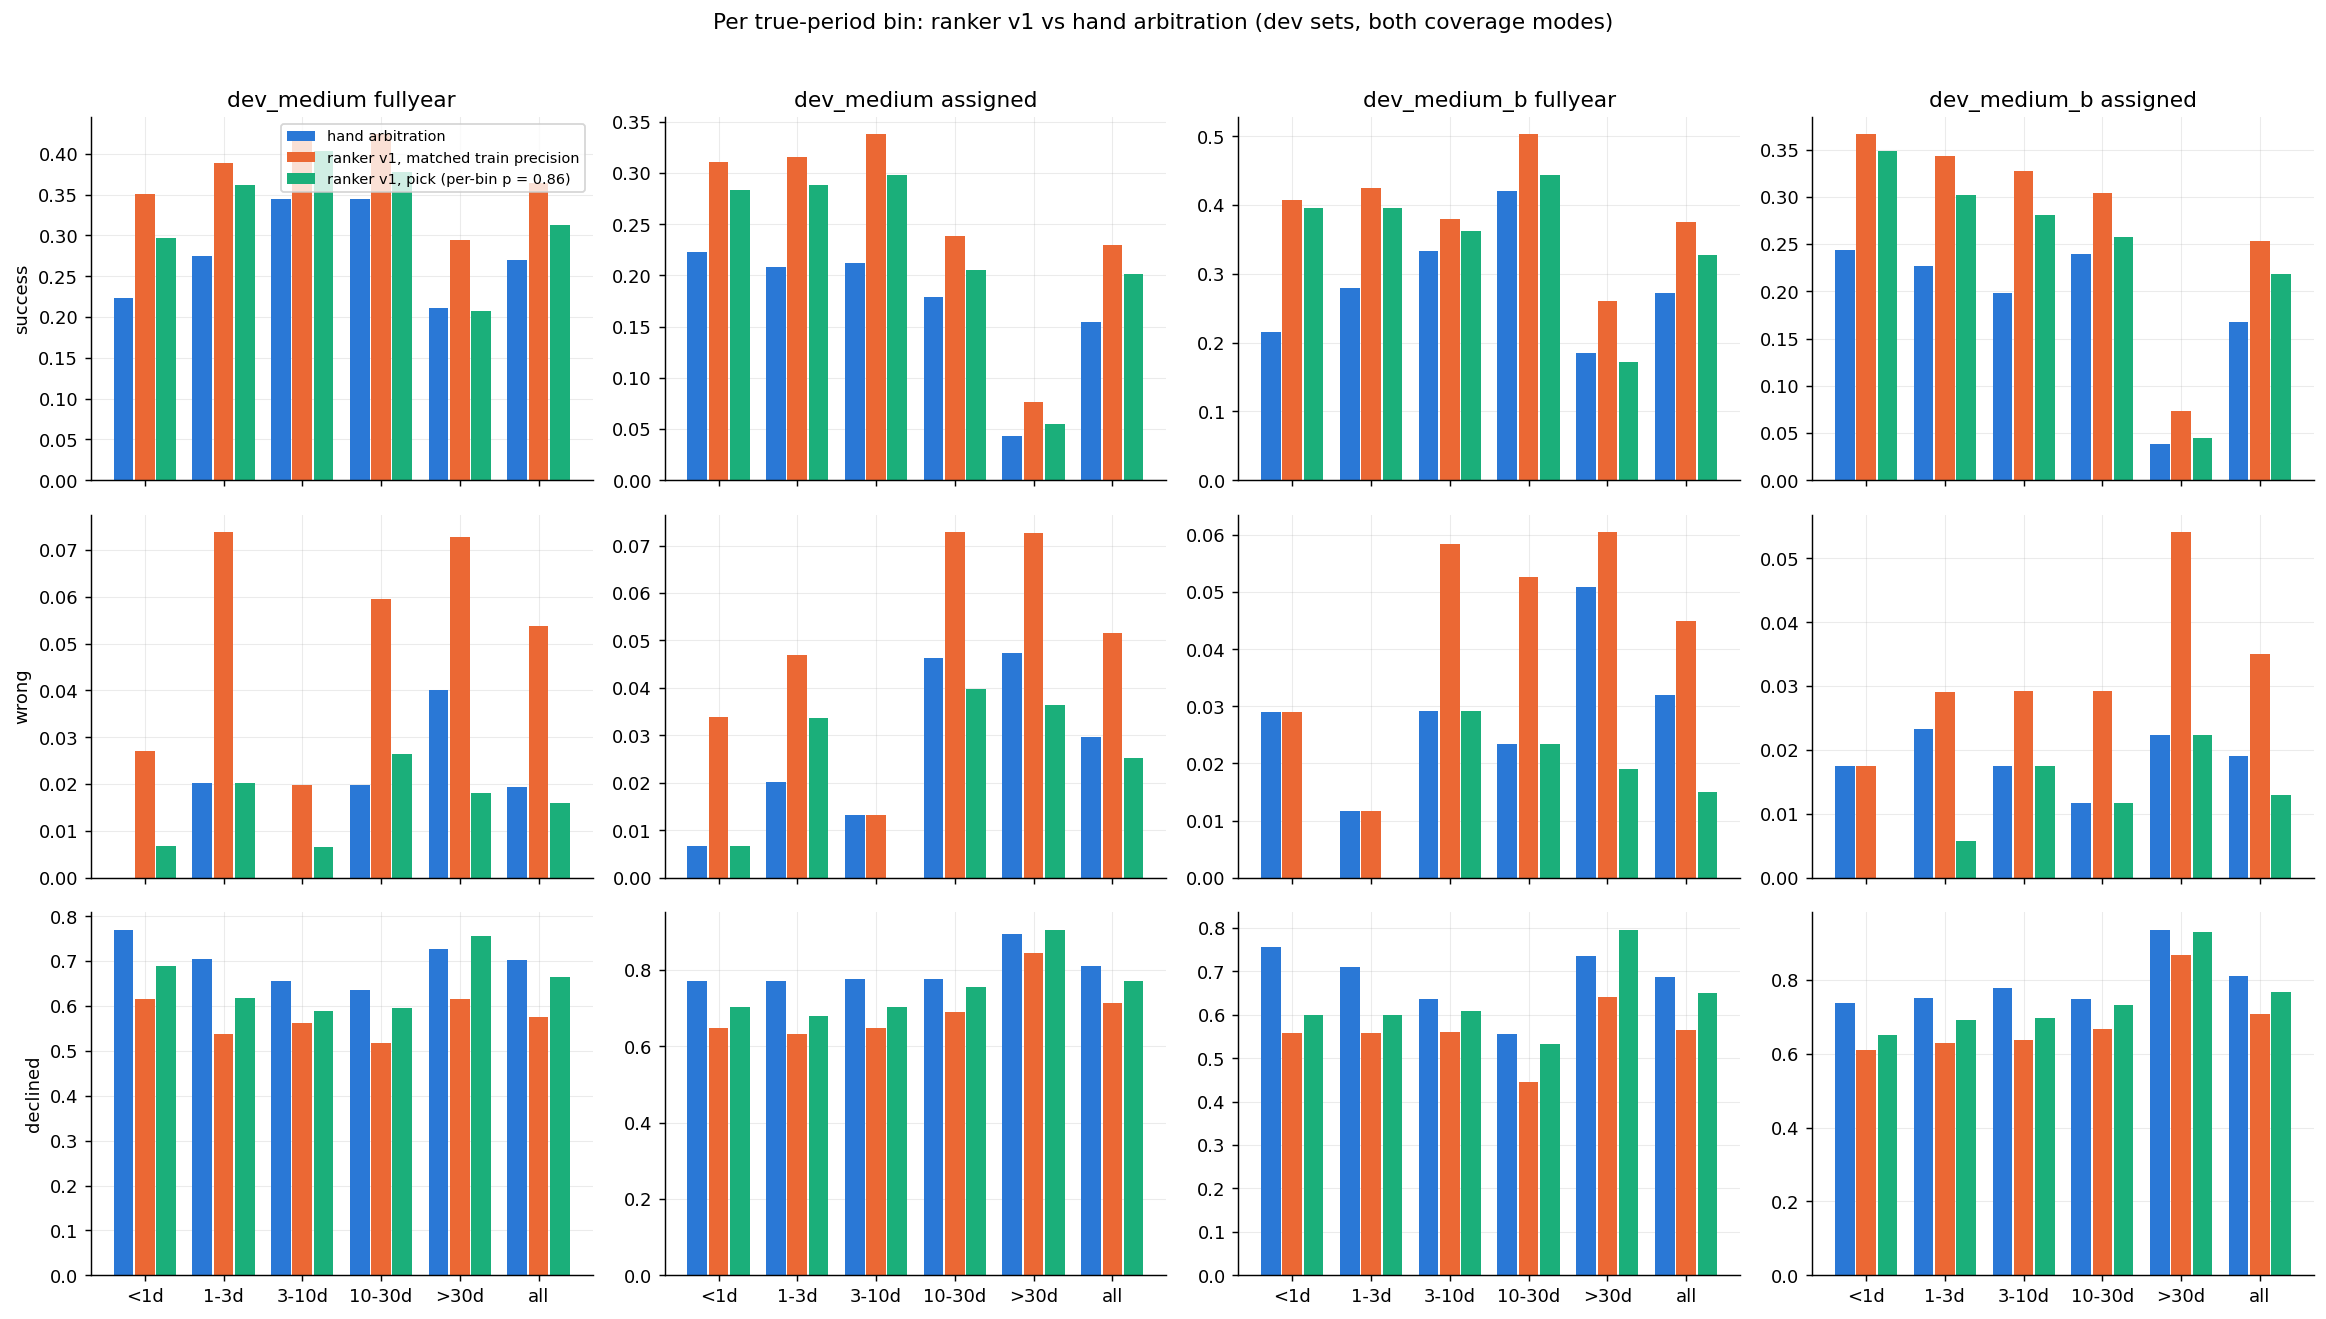

In [5]:
F.per_bin(); display(Image('figures/fig_per_bin.png'))

## < 1 d success at matched precision and at the pick

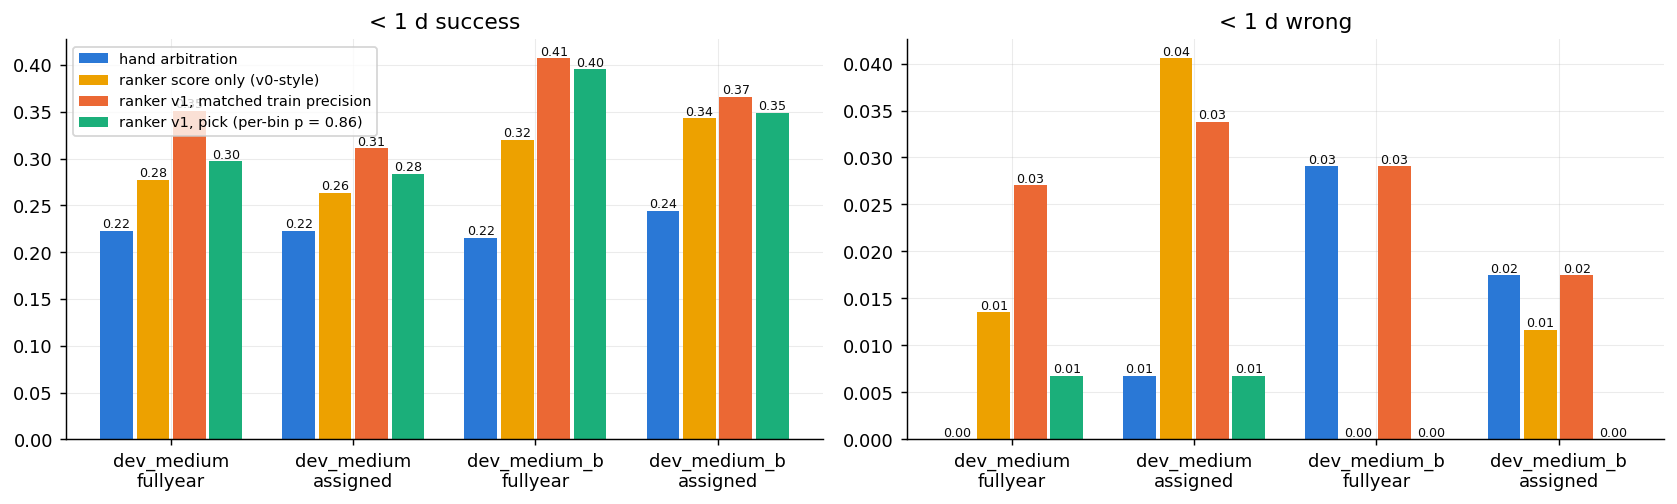

In [6]:
F.lt1d(); display(Image('figures/fig_lt1d.png'))

## Feature importance (grouped permutation on OOF; decline-model gain)

,group,n_features,drop_top1_success,drop_head_auc,base_top1,base_auc
0,family:alias_sph,6,0.0818,0.1565,0.3623,0.8945
1,family:coverage_reach,13,0.0010,0.0082,0.3623,0.8945
2,family:gates,22,0.0093,0.0058,0.3623,0.8945
3,method:wavelet,5,0.0168,0.0052,0.3623,0.8945
4,family:method_spectrum,34,0.0438,0.0046,0.3623,0.8945
5,method:lombscargle,6,0.0033,0.0042,0.3623,0.8945
6,family:star_level,10,0.0001,0.0040,0.3623,0.8945
7,method:lombscargle_short,5,-0.0001,0.0026,0.3623,0.8945
8,family:provenance,8,0.0014,0.0008,0.3623,0.8945
9,method:pairwise_histogram,4,-0.0001,0.0006,0.3623,0.8945


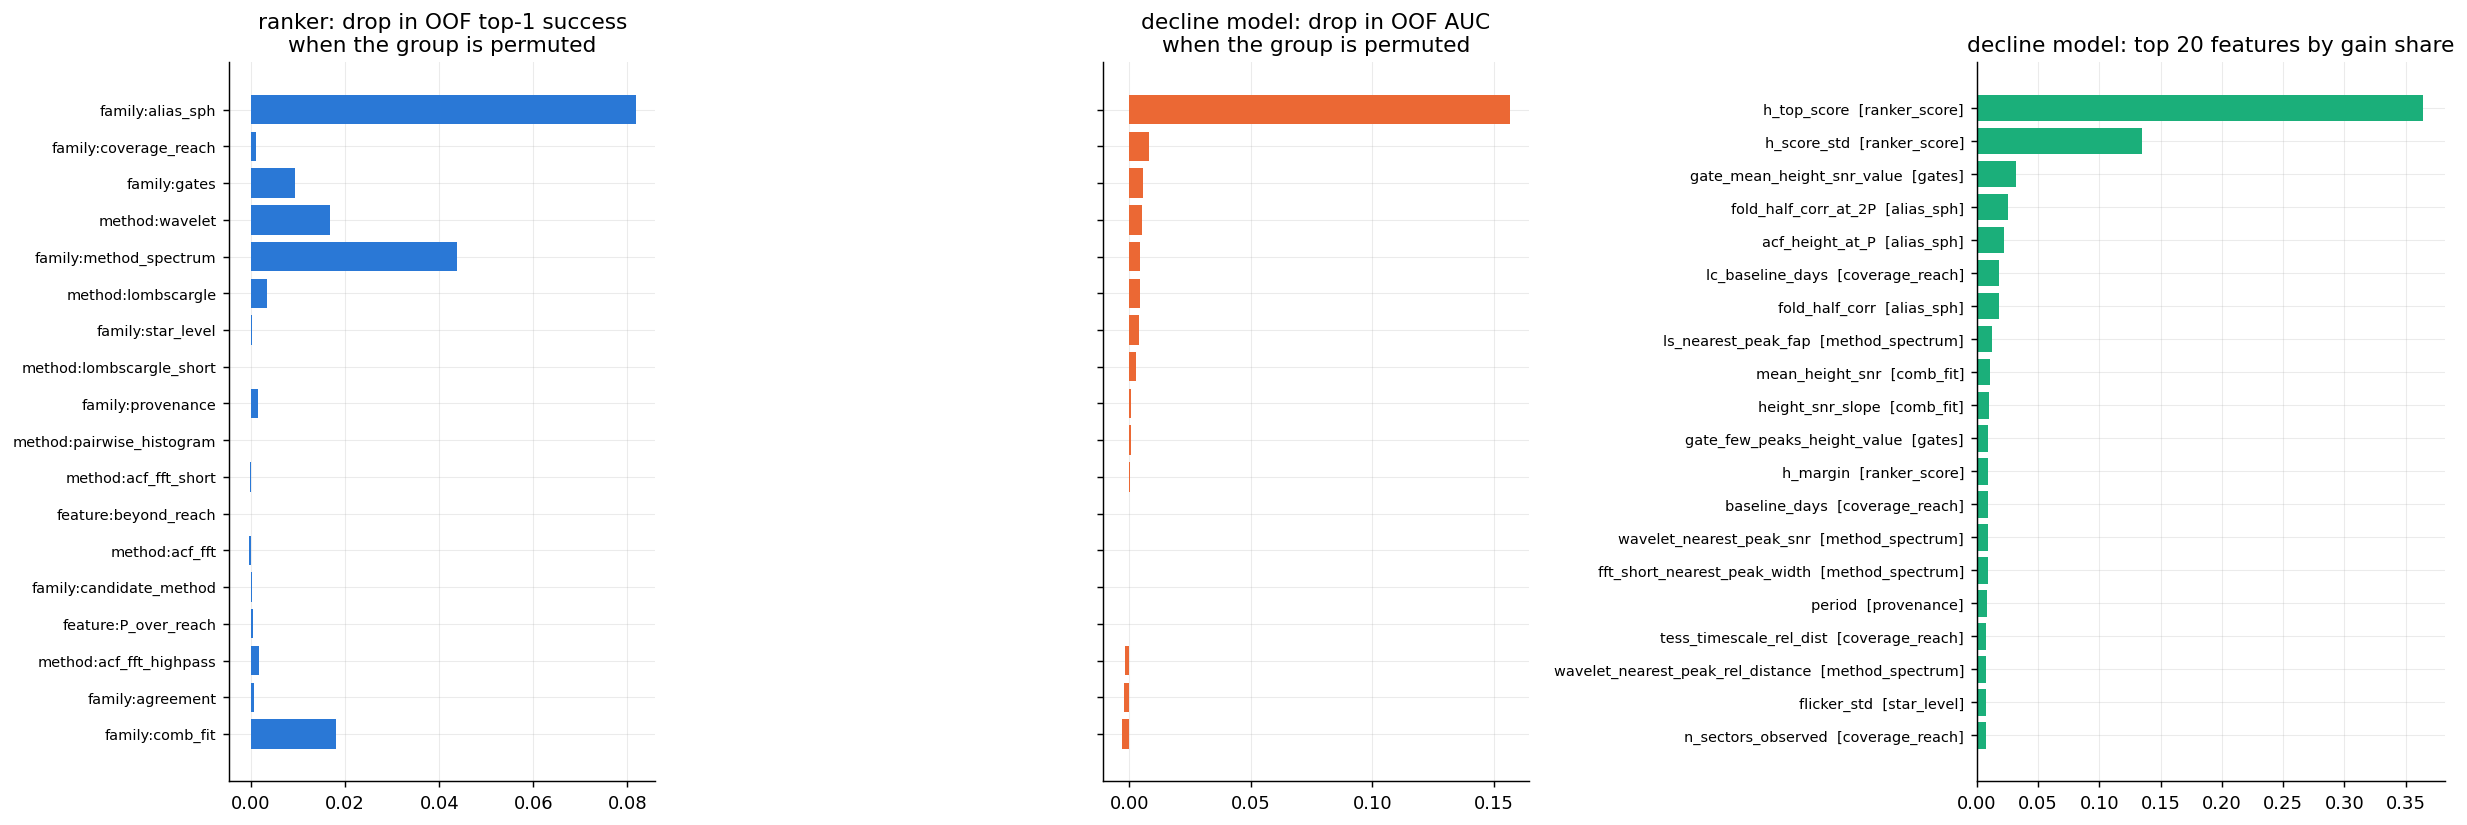

In [7]:
display(pd.read_csv('data/importance_permutation.csv').round(4))
F.importance(); display(Image('figures/fig_importance.png'))

## `half_snr_min` ablation
The same pipeline with and without the three half-coherence columns. Left: OOF purity–completeness. Middle and right: per-bin success (bars) and wrong (ticks) on dev_medium_b at each run's two-set pick (tuned on dev_medium).

,run,family,tuned_on,judged_on,mode,pick,success,wrong,hand_success,hand_wrong,passes,half
0,base,head_perbin,dev_medium,dev_medium_b,fullyear,0.86,0.328,0.015,0.272,0.032,True,False
1,base,head_perbin,dev_medium,dev_medium_b,assigned,0.86,0.218,0.013,0.168,0.019,True,False
2,base,head_perbin,dev_medium_b,dev_medium,fullyear,0.84,0.324,0.030,0.270,0.019,False,False
3,base,head_perbin,dev_medium_b,dev_medium,assigned,0.84,0.209,0.029,0.154,0.030,True,False
8,alt,head_perbin,dev_medium,dev_medium_b,fullyear,0.85,0.325,0.014,0.272,0.032,True,True
9,alt,head_perbin,dev_medium,dev_medium_b,assigned,0.85,0.219,0.012,0.168,0.019,True,True
10,alt,head_perbin,dev_medium_b,dev_medium,fullyear,0.82,0.325,0.034,0.270,0.019,False,True
11,alt,head_perbin,dev_medium_b,dev_medium,assigned,0.82,0.211,0.033,0.154,0.030,False,True


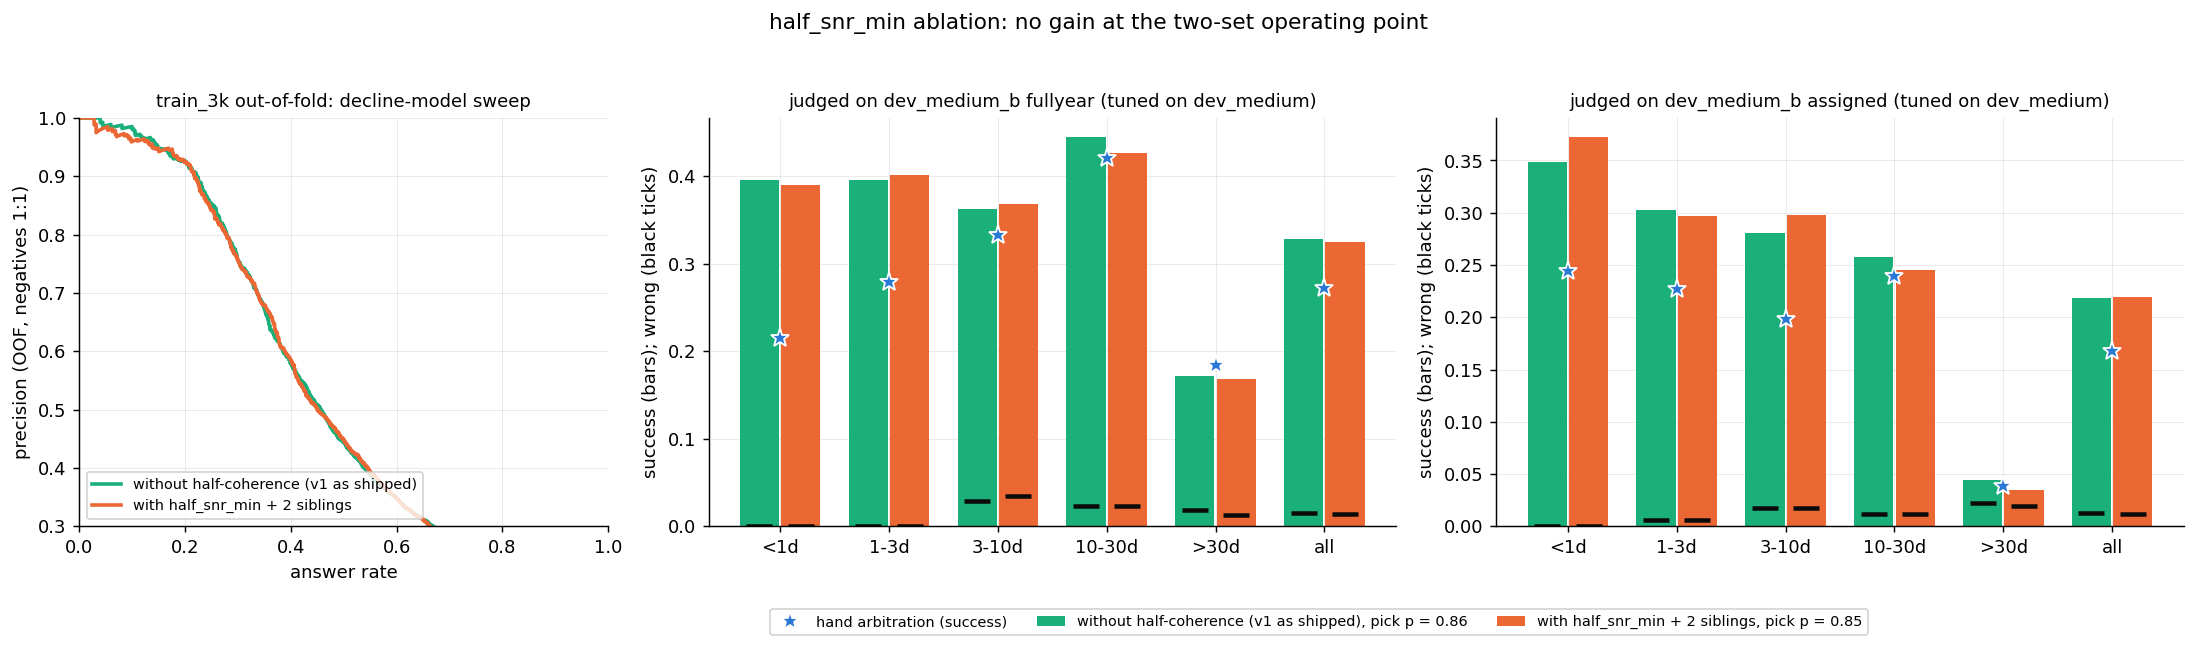

In [8]:
t = pd.read_csv('data/ablation_tuning.csv')
display(t[t.family == 'head_perbin'].round(3))
F.ablation_half(); display(Image('figures/fig_ablation_half.png'))

## Failure modes: where the pick loses to hand

kind                                answered alias  answered wrong  \
set          mode     side                                           
dev_medium   assigned ranker loses               0               1   
                      ranker wins                0               0   
             fullyear ranker loses               1               0   
                      ranker wins                0               0   
dev_medium_b assigned ranker loses               1               0   
                      ranker wins                0               0   
             fullyear ranker loses               2               0   
                      ranker wins                0               0   

kind                                declined, top-1 right  \
set          mode     side                                  
dev_medium   assigned ranker loses                      5   
                      ranker wins                       0   
             fullyear ranker loses                     17   
                      ranker wins                       0   
dev_medium_b assigned ranker loses                     11   
                      ranker wins                       0   
             fullyear ranker loses                     19   
                      ranker wins                       0   

kind                                declined, top-1 wrong  win  
set          mode     side                                      
dev_medium   assigned ranker loses                      0    0  
                      ranker wins                       0   47  
             fullyear ranker loses                      0    0  
                      ranker wins                       0   55  
dev_medium_b assigned ranker loses                      0    0  
                      ranker wins                       0   62  
             fullyear ranker loses                      1    0  
                      ranker wins                       0   78

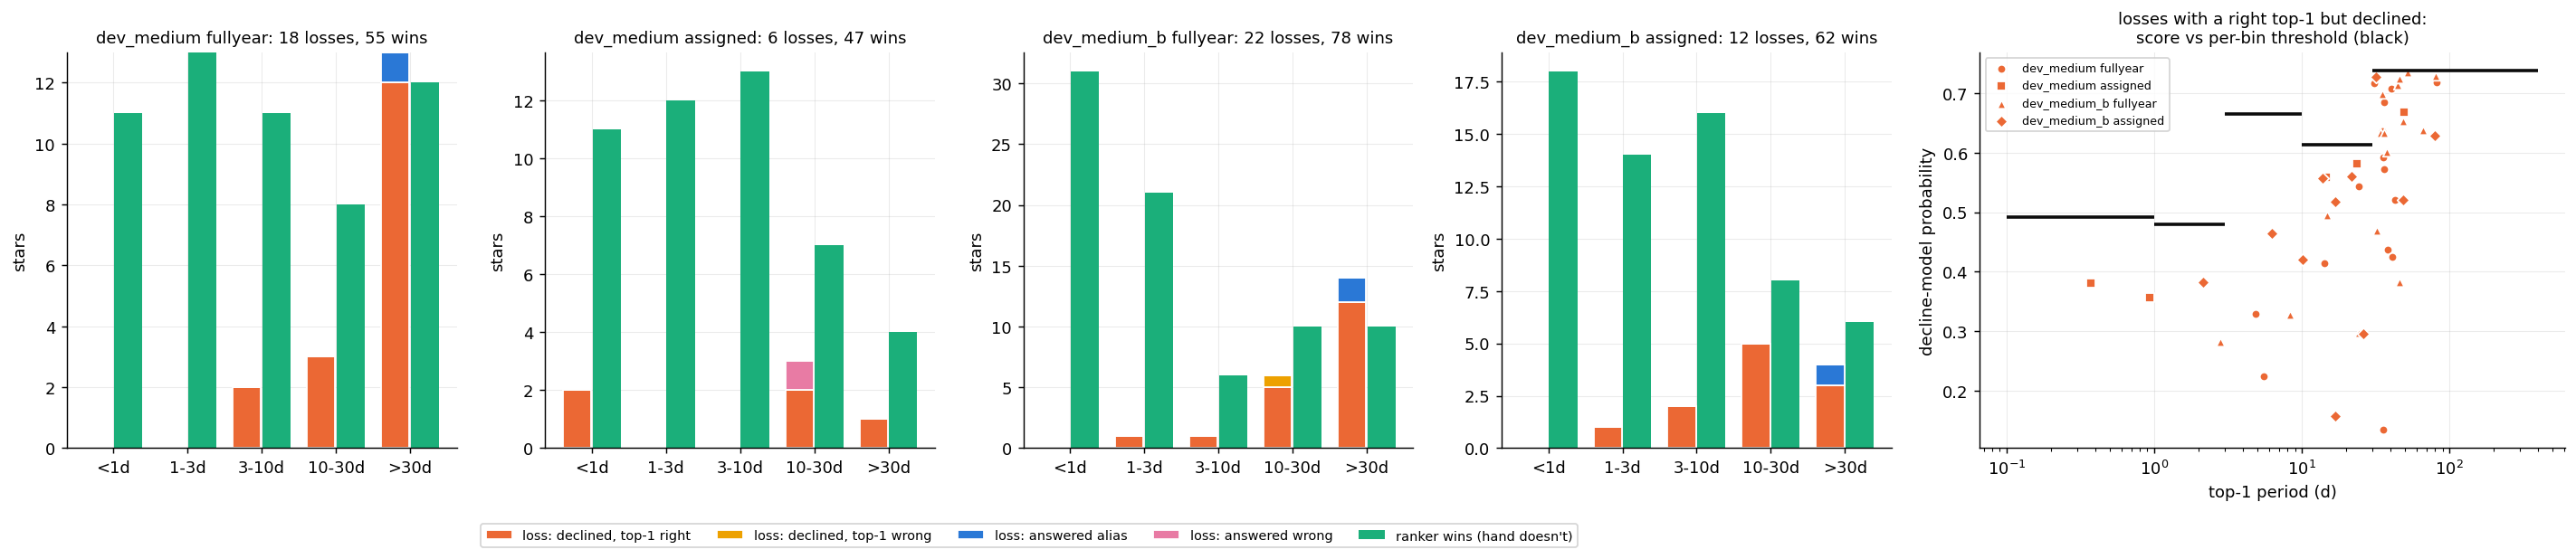

In [9]:
f = pd.read_csv('data/failures.csv')
display(f.groupby(['set', 'mode', 'side', 'kind']).size().unstack(fill_value=0))
F.failure_modes(); display(Image('figures/fig_failure_modes.png'))

## Representative losses

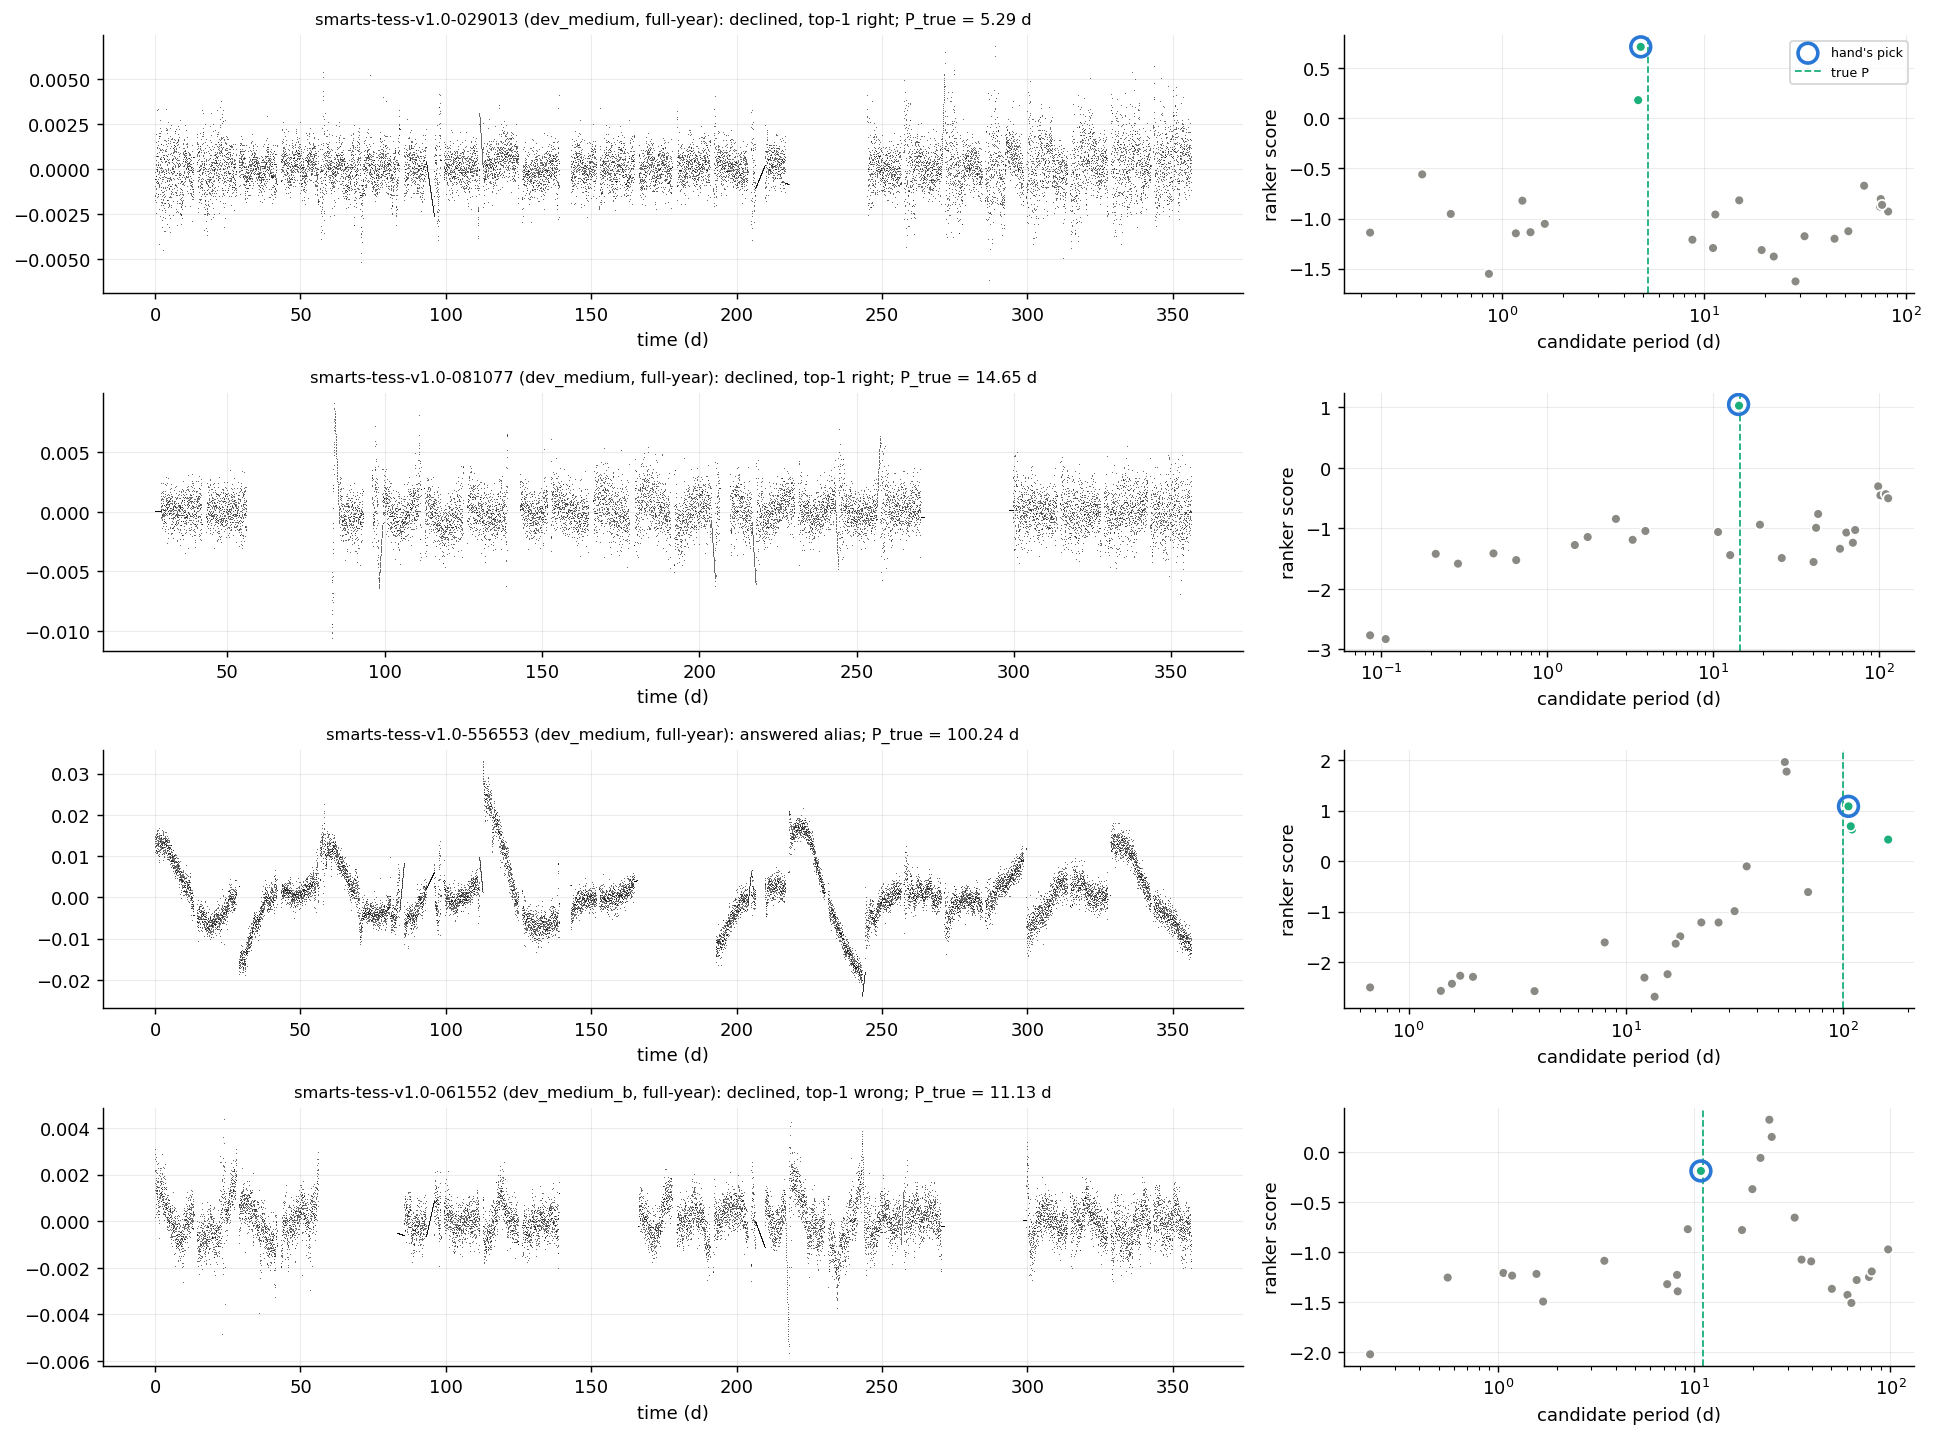

In [10]:
F.examples(); display(Image('figures/fig_examples.png'))